# Лабораторная 6. Построение панорамы

## 1–2. Съёмка и порядок кадров

Панорама собрана из трёх снимков комнаты. Между первым и вторым кадрами повторяется сложенная беговая дорожка. На втором и третьем виден один и тот же дверной проём.

[Разбор темы](KZ_Lab6.md) · [Условие](../task_text.md)

In [1]:
%matplotlib inline

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.patches import Rectangle

`show_row` выводит кадры в одной строке. OpenCV хранит их в BGR, поэтому перед показом переводим цвета в RGB для Matplotlib.

In [2]:
def show_row(images, titles, width=4):
    fig, axes = plt.subplots(
        1, len(images), figsize=(width * len(images), 3.5),
        squeeze=False, layout="constrained",
    )
    for ax, image, title in zip(axes[0], images, titles):
        ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    plt.close(fig)
    return fig

Файлы лежат рядом с `KZ_Lab6.py`. `sorted` располагает `photo_1.JPG`, `photo_2.JPG` и `photo_3.JPG` в порядке съёмки. После учёта ориентации JPEG уменьшаем каждый кадр с $4284 \times 5712$ до $900 \times 1200$ пикселей.

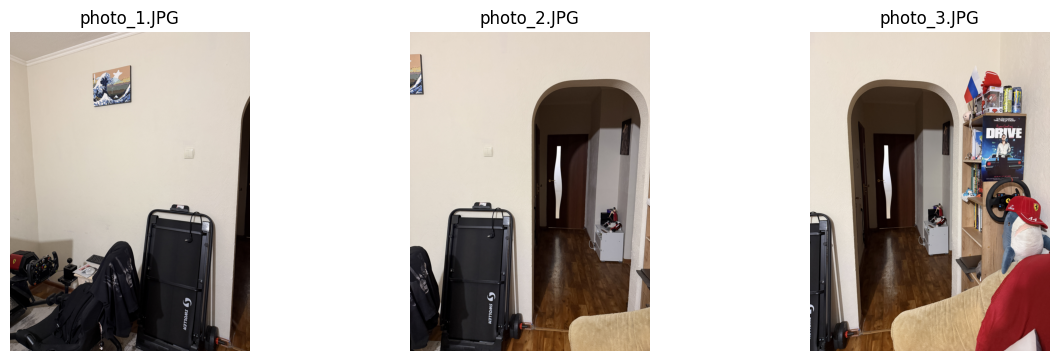

In [3]:
candidates = (Path("."), Path(".."), Path("computer-vision/sfedu/Lab6"))
lab_dir = next((folder for folder in candidates if (folder / "KZ_Lab6.py").is_file()), Path("."))
names = sorted(["photo_1.JPG", "photo_2.JPG", "photo_3.JPG"])

frames = []
for _name in names:
    _data = np.fromfile(lab_dir / _name, dtype=np.uint8)
    _frame = cv2.imdecode(_data, cv2.IMREAD_COLOR)
    _h, _w = _frame.shape[:2]
    _scale = 1200 / max(_h, _w)
    if _scale < 1:
        _size = (max(1, round(_w * _scale)), max(1, round(_h * _scale)))
        _frame = cv2.resize(_frame, _size, interpolation=cv2.INTER_AREA)
    frames.append(_frame)

display(show_row(frames, names))

## 3. Ключевые точки SIFT

На раме дорожки и краях дверного проёма яркость меняется в нескольких направлениях. По таким участкам SIFT находит точки и описывает их окрестности.

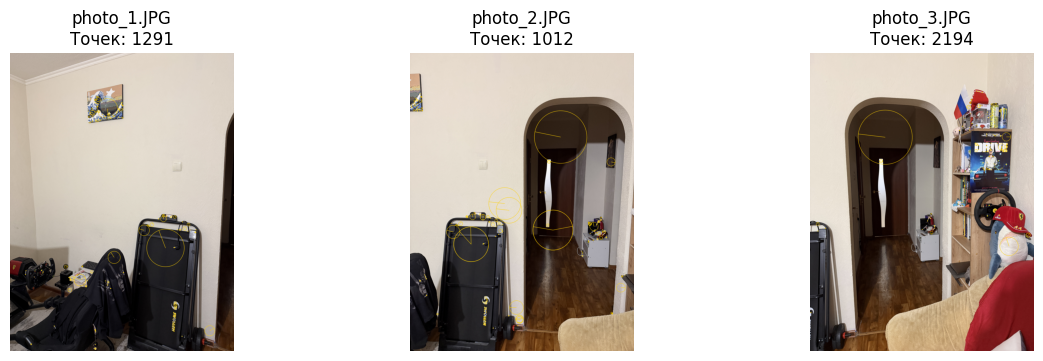

In [4]:
sift = cv2.SIFT_create(nfeatures=3000)
features = [
    sift.detectAndCompute(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY), None)
    for frame in frames
]

keypoint_views = [
    cv2.drawKeypoints(
        frame, sorted(points, key=lambda point: point.response, reverse=True)[:200],
        None, color=(0, 210, 255), flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
    )
    for frame, (points, _) in zip(frames, features)
]
show_row(
    keypoint_views,
    [f"{name}\nТочек: {len(points)}" for name, (points, _) in zip(names, features)],
)

На первом, втором и третьем кадрах найдено 1291, 1012 и 2194 точки соответственно. На третьем снимке виден стеллаж с мелкими деталями. Рисуем по 200 точек с наибольшим откликом, а для сопоставления берём все.

## 4. Сопоставление соседних кадров и гомография

Для каждого дескриптора следующего кадра ищем два ближайших в предыдущем кадре. Критерий Лоу пропускает совпадение, если первый кандидат заметно ближе второго. По оставшимся парам RANSAC оценивает гомографию.

Для точки на раме дорожки в `photo_3.JPG` ближайший кандидат в `photo_2.JPG` имеет расстояние $126.49$, второй $332.91$. Эта пара проходит критерий Лоу, потому что $126.49 < 0.75 \cdot 332.91$.

Точки `_src` берём из следующего снимка, `_dst` из предыдущего. Гомография переносит точку на раме в $(371.36,691.61)$, а её найденное положение в предыдущем кадре равно $(372.31,692.35)$. Ошибка около $1.21$ пикселя. RANSAC принимает эту пару при пороге $3$ пикселя.

photo_2.JPG → photo_1.JPG | Лоу: 219 | RANSAC: 135 | медианная ошибка: 1.19 px
[[ 5.76016574e-01  5.54294543e-03  4.17986891e+02]
 [-2.71446617e-01  9.54612606e-01  4.99028100e+01]
 [-4.59241077e-04  4.16994696e-05  1.00000000e+00]]
photo_3.JPG → photo_2.JPG | Лоу: 287 | RANSAC: 146 | медианная ошибка: 1.07 px
[[ 7.15480749e-01 -3.04184331e-02  3.49887043e+02]
 [-1.15941002e-01  9.65400410e-01  1.81922882e+01]
 [-2.71638536e-04  2.77837481e-05  1.00000000e+00]]


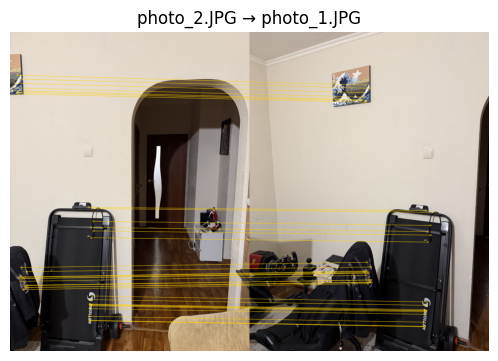

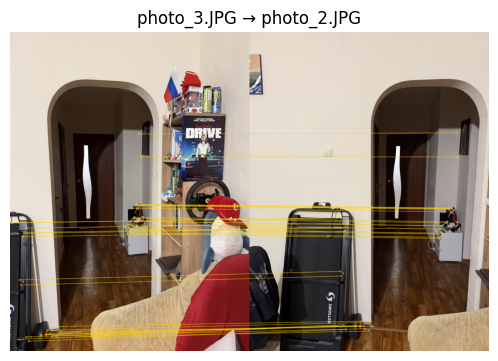

In [5]:
cv2.setRNGSeed(0)
matcher = cv2.BFMatcher(cv2.NORM_L2)
pair_homographies = []
_views = []
for _i in range(1, len(frames)):
    _title = f"{names[_i]} → {names[_i - 1]}"
    _prev_points, _prev_desc = features[_i - 1]
    _curr_points, _curr_desc = features[_i]
    _neighbors = matcher.knnMatch(_curr_desc, _prev_desc, k=2)
    _good = [
        pair[0] for pair in _neighbors
        if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance
    ]
    if len(_good) < 4:
        raise ValueError(f"{_title}: для гомографии нужно хотя бы четыре совпадения")

    _src = np.float32([_curr_points[m.queryIdx].pt for m in _good])
    _dst = np.float32([_prev_points[m.trainIdx].pt for m in _good])
    _H, _mask = cv2.findHomography(_src, _dst, cv2.RANSAC, 3.0)
    if _H is None or not np.isfinite(_H).all() or _mask.sum() < 4:
        raise ValueError(f"{_title}: RANSAC не нашёл гомографию")
    pair_homographies.append(_H)

    _inliers = _mask.ravel().astype(bool)
    _projected = cv2.perspectiveTransform(_src[_inliers, None, :], _H)[:, 0, :]
    _error = np.median(np.linalg.norm(_projected - _dst[_inliers], axis=1))
    _matches = [m for m, keep in zip(_good, _inliers) if keep]
    print(
        f"{_title} | Лоу: {len(_good)} | RANSAC: {len(_matches)}"
        f" | медианная ошибка: {_error:.2f} px"
    )
    print(_H)
    _sample = _matches[::max(1, len(_matches) // 35)][:35]
    _view = cv2.drawMatches(
        frames[_i], _curr_points, frames[_i - 1], _prev_points, _sample,
        None, matchColor=(0, 210, 255), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
    )
    _views.append(show_row([_view], [_title], width=9))
for _figure in _views:
    display(_figure)

RANSAC принял 135 из 219 пар между вторым и первым кадрами и 146 из 287 между третьим и вторым. Медианные ошибки равны $1.19$ и $1.07$ пикселя. На рисунках видно часть совпадений около дорожки и дверного проёма.

## 5. Общие координаты и размеры холста

Перемножаем парные матрицы, чтобы перенести все кадры в координаты
первого. Преобразуем четыре угла каждого кадра и находим границы.
Сдвиг переводит минимальные координаты холста в `(0, 0)`.

Чтобы перенести точку из `photo_3.JPG` в `photo_1.JPG`, сначала применяем $H(1,2)$, затем $H(0,1)$. Так точка на раме проходит через $(371.36,691.61)$ и попадает в $(740.68,709.92)$ в координатах первого кадра. В произведении $H(0,1)H(1,2)$ правая матрица действует первой.

In [6]:
transforms = [np.eye(3)]
for _H in pair_homographies:
    transforms.append(transforms[-1] @ _H)

_outlines = []
for _frame, _H in zip(frames, transforms):
    _h, _w = _frame.shape[:2]
    _corners = np.float64([[0, 0], [_w - 1, 0], [_w - 1, _h - 1], [0, _h - 1]])
    _denominator = _corners @ _H[2, :2] + _H[2, 2]
    if (
        _denominator.min() <= 0 <= _denominator.max()
        or np.any(np.abs(_denominator) < 1e-8)
    ):
        raise ValueError("Один из кадров выходит за горизонт проекции первого кадра")
    _outlines.append(cv2.perspectiveTransform(_corners[None], _H)[0])

_corners = np.concatenate(_outlines)
_lo = np.floor(_corners.min(axis=0))
_hi = np.ceil(_corners.max(axis=0))
_size = _hi - _lo + 1
if not np.isfinite(_size).all() or _size.prod() > 16_000_000:
    raise ValueError("Холст слишком велик. Проверь порядок и перекрытие кадров")

shift = np.array([[1, 0, -_lo[0]], [0, 1, -_lo[1]], [0, 0, 1]])
canvas_size = tuple(map(int, _size))
canvas_transforms = [shift @ H for H in transforms]
outlines = [outline - _lo for outline in _outlines]
print(f"Размер холста: {canvas_size[0]} × {canvas_size[1]} пикселей")

Размер холста: 2998 × 3097 пикселей


Крайние углы в координатах первого кадра задают границы $x$ от $0$ до $2997$, $y$ от $-1061$ до $2035$. Прибавляем $1061$ к $y$ и получаем холст $2998 \times 3097$. В широкой серии из шести снимков четвёртый кадр пересекал горизонт проекции первого, поэтому в примере использованы три соседних снимка.

## 6. Склейка кадров

Переносим изображения и маски их покрытия на холст через `warpPerspective`.
В зоне перекрытия усредняем цвета с весами по расстоянию до края кадра.

Маска хранит, какие пиксели холста покрыты кадром. Тёмная рама дорожки сохраняется на маске. На перекрытии около арки `distanceTransform` даёт больший вес кадру, чей край дальше от текущего пикселя.

In [7]:
_width, _height = canvas_size
_color_sum = np.zeros((_height, _width, 3), dtype=np.float32)
_weight_sum = np.zeros((_height, _width), dtype=np.float32)
for _frame, _H in zip(frames, canvas_transforms):
    _warped = cv2.warpPerspective(_frame, _H, canvas_size, borderMode=cv2.BORDER_REPLICATE)
    _mask = np.ones(_frame.shape[:2], dtype=np.uint8)
    _mask = cv2.warpPerspective(_mask, _H, canvas_size, flags=cv2.INTER_NEAREST)
    _weights = cv2.distanceTransform(np.pad(_mask, 1), cv2.DIST_L2, 3)[1:-1, 1:-1]
    _color_sum += _warped * _weights[:, :, None]
    _weight_sum += _weights

covered = _weight_sum > 0
np.divide(_color_sum, _weight_sum[:, :, None], out=_color_sum, where=covered[:, :, None])
canvas = np.clip(np.rint(_color_sum), 0, 255).astype(np.uint8)

## 7. Обрезка по маске покрытия

Ищем прямоугольник наибольшей площади, целиком покрытый фотографиями.
На первом рисунке видны границы кадров и окно обрезки. На втором
показана готовая панорама.

На каждой строке считаем длину цепочки покрытых пикселей в каждом столбце. Например, высоты $[0,3,3,1]$ дают прямоугольник шириной $2$ и высотой $3$ в двух средних столбцах. Так можно найти область наибольшей площади, в которой все пиксели покрыты фотографиями.

In [8]:
def largest_covered_rectangle(covered):
    heights = np.zeros(covered.shape[1], dtype=int)
    best_area = 0
    best = None
    for y, row in enumerate(covered):
        heights = np.where(row, heights + 1, 0)
        stack = []
        for x, height in enumerate(heights.tolist() + [0]):
            left = x
            while stack and stack[-1][1] > height:
                left, previous_height = stack.pop()
                area = (x - left) * previous_height
                if area > best_area:
                    best_area = area
                    best = (left, y + 1 - previous_height, x, y + 1)
            if height and (not stack or stack[-1][1] < height):
                stack.append((left, height))
    if best is None:
        raise ValueError("После преобразования холст пуст")
    return best

Размер панорамы: 2453 × 1200 пикселей
Доля покрытых пикселей: 100.0%


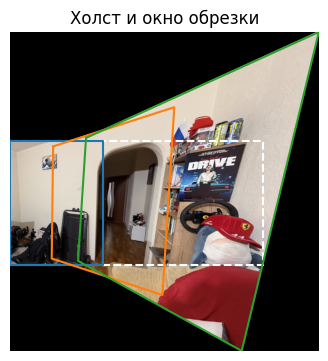

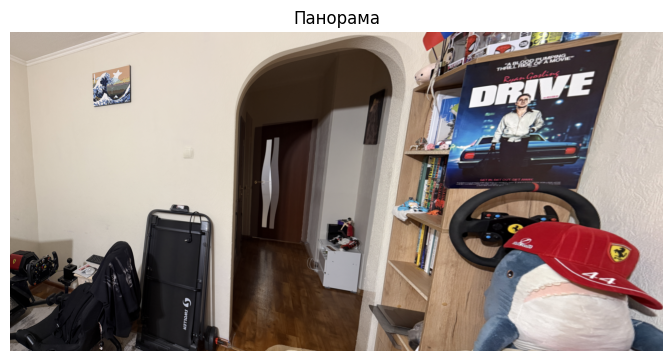

In [9]:
crop = largest_covered_rectangle(covered)
x0, y0, x1, y1 = crop
panorama = canvas[y0:y1, x0:x1].copy()

canvas_fig = show_row([canvas], ["Холст и окно обрезки"], width=10)
_ax = canvas_fig.axes[0]
for _i, _outline in enumerate(outlines):
    _loop = _outline[[0, 1, 2, 3, 0]]
    _ax.plot(_loop[:, 0], _loop[:, 1], color=f"C{_i}", linewidth=1.5)
_ax.add_patch(Rectangle(
    (x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0,
    edgecolor="white", facecolor="none", linewidth=1.5, linestyle="--",
))
print(f"Размер панорамы: {x1 - x0} × {y1 - y0} пикселей")
print(f"Доля покрытых пикселей: {covered[y0:y1, x0:x1].mean():.1%}")
display(canvas_fig)
display(show_row([panorama], ["Панорама"], width=10))

Пунктир ограничивает итоговый прямоугольник $2453 \times 1200$. Его покрытие равно $100\%$. Плакат справа растянут при переносе третьего кадра на плоскость первого. Следующая ячейка сохраняет `panorama.png` рядом со снимками.

In [ ]:
output_path = lab_dir / "panorama.png"
ok, encoded = cv2.imencode(".png", panorama)
if not ok:
    raise RuntimeError("Не удалось закодировать панораму")
output_path.write_bytes(encoded.tobytes())
print(output_path.name)